# Robustness of VaDeSC on SUPPORT (baseline-only)

The robustness checks from the project plan, on SUPPORT without the post-baseline variables, with several seeds (notebook 01 had single runs on the leaky data):

1. **Number of clusters** K = 1, 2, 3, 4, 6, 8
2. **Survival distribution**: Weibull with fixed shape k = 1 or 2, Weibull with a learned shape, log-normal
3. **Stability across data splits**, not only across seeds: do models trained on different splits put the same patients together?

Default config as in the paper (`configs/support.yml`): K = 4, 16 latent dimensions, Weibull k = 2, 300 epochs. Model seeds 0, 1, 2.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score

from src.data import load_support
from src.vadesc import VaDeSC, evaluate_vadesc, tensor, train_vadesc

SEEDS = [0, 1, 2]
SPLITS = [42, 1, 2]  # 42 = the split used in all other notebooks
EPOCHS = 300
data = {s: load_support(drop_post_baseline=True, seed=s) for s in SPLITS}
d = data[42]

class VaDeSCLearnK(VaDeSC):
    # same model, but the Weibull shape k is learned (initialised at weibull_k)
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.learn_k = True

def fit(d, seed, K=4, d_lat=16, **kw):
    model = train_vadesc(d, K=K, d_lat=d_lat, epochs=EPOCHS, seed=seed, **kw)
    m, cl, _ = evaluate_vadesc(model, d)
    return model, m, cl

def all_patients_clusters(model, d):
    # cluster of every patient (train + validation + test), in the original row order
    X = np.concatenate([d.X_tr, d.X_va, d.X_te])
    order = np.concatenate([d.idx["tr"], d.idx["va"], d.idx["te"]])
    _, gamma = model.predict(tensor(X))
    out = np.empty(len(order), dtype=int)
    out[order] = gamma.argmax(1).cpu().numpy()
    return out

## 1. Number of clusters

"used clusters" = how many clusters actually receive test patients.

In [2]:
rows, models = [], {}
for K in [1, 2, 3, 4, 6, 8]:
    for s in SEEDS:
        model, m, cl = fit(d, s, K=K)
        if K == 4:
            models[(42, s)] = model
        rows.append({"K": K, "seed": s, "C-index": m["C-index"], "IBS": m["IBS"], "log-rank chi2": m["log-rank chi2"],
                     "used clusters": len(np.unique(cl)), "smallest cluster": np.bincount(cl).min() / len(cl)})
    print("K", K, "done", flush=True)
ks = pd.DataFrame(rows)
ks.to_csv("../results/robust_K.csv", index=False)
ks.groupby("K")[["C-index", "IBS", "log-rank chi2", "used clusters", "smallest cluster"]].agg(["mean", "std"]).round(3)

K 1 done


K 2 done


K 3 done


K 4 done


K 6 done


K 8 done


C-index           IBS        log-rank chi2         used clusters       \
     mean    std   mean    std          mean     std          mean  std   
K                                                                         
1   0.691  0.046  0.265  0.051           NaN     NaN           1.0  0.0   
2   0.683  0.025  0.196  0.005       281.030  22.280           2.0  0.0   
3   0.679  0.017  0.201  0.005       321.607  45.083           3.0  0.0   
4   0.670  0.017  0.205  0.005       250.120  54.183           4.0  0.0   
6   0.634  0.015  0.207  0.002       272.772  59.370           6.0  0.0   
8   0.673  0.012  0.202  0.007       351.520  88.304           8.0  0.0   

  smallest cluster         
              mean    std  
K                          
1            1.000  0.000  
2            0.252  0.029  
3            0.044  0.016  
4            0.036  0.015  
6            0.022  0.010  
8            0.008  0.003

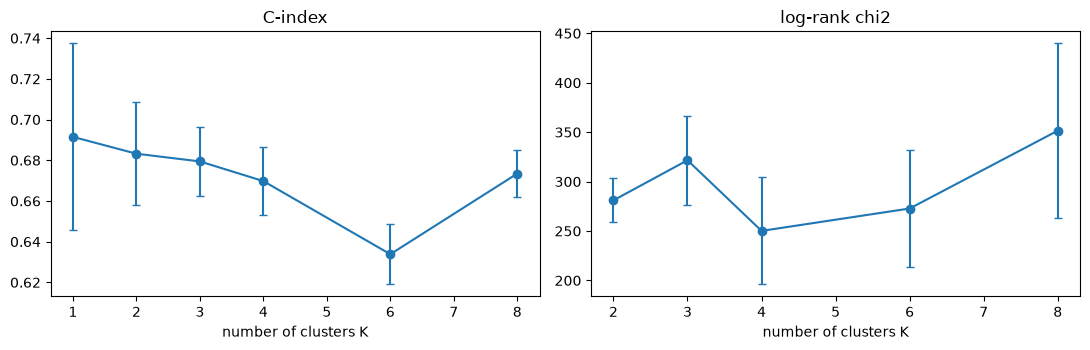

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
g = ks.groupby("K")
for a, col in zip(ax, ["C-index", "log-rank chi2"]):
    a.errorbar(g[col].mean().index, g[col].mean(), yerr=g[col].std(), marker="o", capsize=3)
    a.set(xlabel="number of clusters K", title=col)
plt.tight_layout(); plt.show()

## 2. Survival distribution

In [4]:
rows = []
for name, kw in [("Weibull, k = 2 (paper)", dict(weibull_k=2.0)), ("Weibull, k = 1", dict(weibull_k=1.0)),
                 ("Weibull, learned k", dict(weibull_k=1.0, model_cls=VaDeSCLearnK)), ("log-normal", dict(dist="lognormal"))]:
    for s in SEEDS:
        if name.startswith("Weibull, k = 2"):
            m = ks[(ks.K == 4) & (ks.seed == s)].iloc[0].to_dict()  # same runs as K = 4 above
            k_hat = 2.0
        else:
            model, m, _ = fit(d, s, **kw)
            k_hat = float(model.shape()) if name.startswith("Weibull") else np.nan
        rows.append({"distribution": name, "seed": s, "C-index": m["C-index"], "IBS": m["IBS"],
                     "log-rank chi2": m["log-rank chi2"], "k": k_hat})
    print(name, "done", flush=True)
dist = pd.DataFrame(rows)
dist.to_csv("../results/robust_distribution.csv", index=False)
dist.groupby("distribution", sort=False)[["C-index", "IBS", "log-rank chi2", "k"]].agg(["mean", "std"]).round(3)

Weibull, k = 2 (paper) done


Weibull, k = 1 done


Weibull, learned k done


log-normal done


C-index           IBS        log-rank chi2          \
                          mean    std   mean    std          mean     std   
distribution                                                                
Weibull, k = 2 (paper)   0.670  0.017  0.205  0.005       250.120  54.183   
Weibull, k = 1           0.657  0.007  0.203  0.001       208.590  27.253   
Weibull, learned k       0.702  0.012  0.188  0.005        85.370  18.639   
log-normal               0.711  0.012  0.186  0.005        77.723  12.667   

                           k         
                        mean    std  
distribution                         
Weibull, k = 2 (paper)  2.00  0.000  
Weibull, k = 1          1.00  0.000  
Weibull, learned k      0.59  0.023  
log-normal               NaN    NaN

## 3. Stability across seeds and data splits

Three splits × three model seeds. Every model assigns a cluster to all 9,105 patients, and we compare the clusterings with ARI (1 = identical grouping, 0 = unrelated):
- **same split, different seed**: only the random initialisation differs,
- **different split**: the model also saw different training patients.

C-index is on each model's own test set.

In [5]:
cindex = {}
for sp in SPLITS:
    for s in SEEDS:
        if (sp, s) not in models:
            models[(sp, s)] = train_vadesc(data[sp], K=4, d_lat=16, epochs=EPOCHS, seed=s)
        cindex[(sp, s)] = evaluate_vadesc(models[(sp, s)], data[sp])[0]["C-index"]
    print("split", sp, "done", flush=True)

clust = {key: all_patients_clusters(m, data[key[0]]) for key, m in models.items() if key[0] in SPLITS}
keys = sorted(clust)
pairs = []
for i, a in enumerate(keys):
    for b in keys[i + 1:]:
        pairs.append({"a": a, "b": b, "same split": a[0] == b[0], "ARI": adjusted_rand_score(clust[a], clust[b])})
pairs = pd.DataFrame(pairs)
pairs.to_csv("../results/robust_split_pairs.csv", index=False)
print("C-index per split (mean over seeds):",
      {sp: round(np.mean([cindex[(sp, s)] for s in SEEDS]), 3) for sp in SPLITS})
pairs.groupby("same split")["ARI"].agg(["mean", "std", "min", "max", "count"]).rename(index={True: "same split, different seed", False: "different split"}).round(2)

split 42 done


split 1 done


split 2 done


C-index per split (mean over seeds): {42: np.float64(0.67), 1: np.float64(0.644), 2: np.float64(0.657)}


,mean,std,min,max,count
same split,,,,,
different split,0.56,0.12,0.35,0.79,27
"same split, different seed",0.62,0.10,0.45,0.74,9


## Notes

Baseline-only SUPPORT, 3 model seeds (and 3 splits in section 3).

- **Number of clusters.** More clusters do not improve prediction: K = 1 (one cluster, i.e. a VAE with a Weibull survival model) gives a C-index of 0.691 ± 0.046, K = 2-4 give 0.67-0.68, K = 6 is lowest (0.634). The extra clusters get small: the smallest cluster has 4% of patients for K = 3-4 and under 1% for K = 8. The log-rank statistic does not increase steadily with K either. So on SUPPORT the clusters do not help prediction, which matches notebook 11 (the clusters mainly order patients by severity).
- **Survival distribution.** The paper's fixed Weibull shape k = 2 (hazard increasing over time) fits SUPPORT badly: when k is learned it goes to 0.59 ± 0.02 (hazard decreasing over time, many deaths soon after admission), and the C-index rises from 0.670 to 0.702; log-normal gives 0.711 ± 0.012 and the best IBS (0.186). This is the largest single improvement for VaDeSC on baseline-only SUPPORT, but it is still below Cox (0.73). With the better-fitting distributions the clusters separate survival less (log-rank about 80 vs 250), so better prediction comes with less distinct clusters.
- **Stability.** Over all 9,105 patients, models with the same split but a different seed agree moderately (ARI 0.62 ± 0.10, range 0.45-0.74); models trained on different splits agree slightly less (0.56 ± 0.12, range 0.35-0.79). So most of the instability comes from the random initialisation, and changing the training patients adds a little more. C-index varies between splits too (0.644-0.670).
